# Crystal optics: double refraction, polarizing prisms, optical activity and the Faraday isolator

In a crystal the index depends on the direction of the field: the
dielectric constant is a tensor. A plane wave then splits into two waves
with orthogonal polarizations and different indices, and the energy of one
of them no longer flows along its wave vector. Everything that handles
polarization in optics follows from this: wave plates, polarizing prisms,
the conoscopic figures of mineralogy, and, with a magnetic field or a
chiral crystal, rotation of the plane of polarization.

This notebook uses the `crystals` module:

1. the index ellipsoid: the indices and the walk-off of the two waves in
   uniaxial crystals,
2. double refraction at a crystal surface: calcite and its two images,
3. wave plates at oblique incidence with the 4 × 4 matrix method, and the
   conoscopic figure of a plate cut perpendicular to the optic axis,
4. polarizing prisms: Glan–Taylor, Glan–Foucault and Glan–Thompson
   polarizers and their field of view, Wollaston and Rochon prisms,
5. optical activity: the rotatory dispersion of quartz and its elliptical
   eigenwaves off the axis,
6. Faraday rotation and the optical isolator.

**Conventions.** Fields vary as $e^{i(\mathbf k\cdot\mathbf r - \omega t)}$,
wave vectors are given in units of $k_0 = 2\pi/\lambda$ (their length is
the index of the wave). Jones matrices act on $(E_x, E_y)$; a retarder
delays its slow axis by $e^{+i\delta}$, and rotations are counted
counterclockwise from $x$ to $y$ as seen by an observer looking towards
the source, as in `polarization.jones`. The 4 × 4 method returns Jones
matrices in the $(p, s)$ basis of the plane of incidence, or projected to
the lab $x$–$y$ basis when the azimuth of the plane of incidence is given.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import crystals as cr
from pyoptics.arvr import aplate_retardance
from pyoptics.polarization import jones
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. The index ellipsoid

For a wave normal $\mathbf s$ the displacement $\mathbf D$ lies in the
plane perpendicular to $\mathbf s$, and the two allowed directions of
$\mathbf D$ are the axes of the ellipse in which this plane cuts the index
ellipsoid $\mathbf D^T\varepsilon^{-1}\mathbf D = 1$; the half axes are the
two indices. In a uniaxial crystal one wave, the **ordinary** wave, has
$\mathbf D$ perpendicular to the optic axis and the index $n_o$ in every
direction. The **extraordinary** wave has $\mathbf D$ in the plane of
$\mathbf s$ and the axis, and at the angle $\theta$ to the axis

$$\frac{1}{n^2(\theta)} = \frac{\cos^2\theta}{n_o^2} + \frac{\sin^2\theta}{n_e^2}.$$

Its field $\mathbf E = \varepsilon^{-1}\mathbf D$ is not perpendicular to
$\mathbf s$, so the Poynting vector $\mathbf E\times\mathbf H$ deviates
from the wave normal by the **walk-off** angle $\rho$, with
$\tan(\theta - \rho) = (n_o/n_e)^2\tan\theta$. `cr.wave_indices()` solves the
eigenvalue problem for any tensor, including biaxial ones.

calcite: n_o = 1.6583, n_e = 1.4861, largest walk-off 6.27° at θ = 42.0°
quartz: n_o = 1.5442, n_e = 1.5533, largest walk-off 0.34° at θ = 45.0°


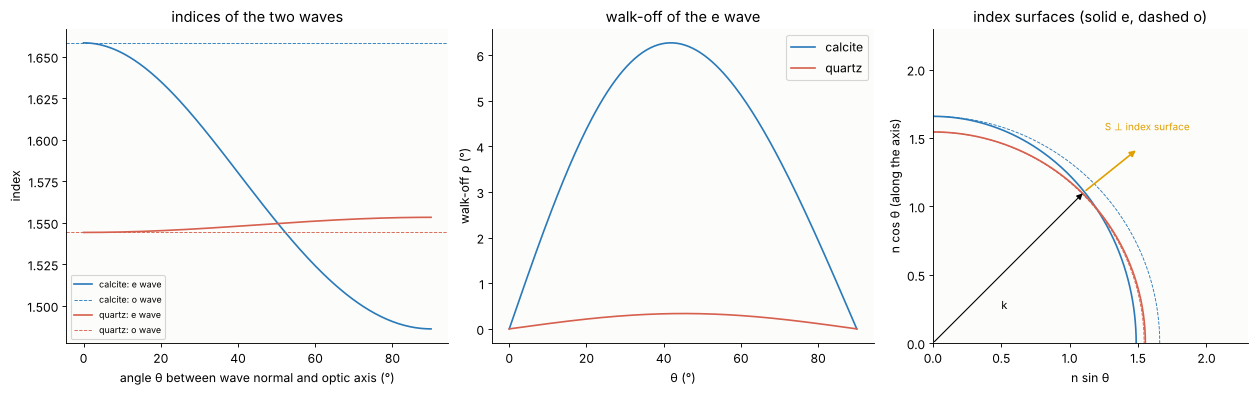

In [2]:
lam = 589.3
n_cal = cr.calcite_indices(lam)
n_qz = cr.quartz_indices(lam)
th = np.radians(np.linspace(0, 90, 181))
dirs = np.stack([np.sin(th), 0*th, np.cos(th)], -1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")
for (no, ne), name, c in ((n_cal, "calcite", BLUE), (n_qz, "quartz", RED)):
    eps = cr.uniaxial_eps(no, ne)                       # optic axis along z
    n, D, E, S = cr.wave_indices(eps, dirs)
    rho = np.degrees(cr.walkoff(eps, dirs))
    # the e wave is the one whose index depends on the angle
    ie = np.argmax(np.abs(n.real - no), axis=-1)
    n_e_th = np.take_along_axis(n.real, ie[:, None], -1)[:, 0]
    rho_e = np.take_along_axis(rho, ie[:, None], -1)[:, 0]
    ax[0].plot(np.degrees(th), n_e_th, color=c, label=f"{name}: e wave")
    ax[0].axhline(no, color=c, ls="--", lw=0.8, label=f"{name}: o wave")
    ax[1].plot(np.degrees(th), rho_e, color=c, label=name)
    k = np.argmax(rho_e)
    print("{}: n_o = {:.4f}, n_e = {:.4f}, largest walk-off {:.2f}° at θ = {:.1f}°".format(
        name, no, ne, rho_e[k], np.degrees(th[k])))
    # index surface (polar plot of n) in the x-z plane
    ax[2].plot(n_e_th*np.sin(th), n_e_th*np.cos(th), color=c)
    ax[2].plot(no*np.sin(th), no*np.cos(th), color=c, ls="--", lw=0.8)
ax[0].set_xlabel("angle θ between wave normal and optic axis (°)"); ax[0].set_ylabel("index")
ax[0].legend(fontsize=8); ax[0].set_title("indices of the two waves")
ax[1].set_xlabel("θ (°)"); ax[1].set_ylabel("walk-off ρ (°)"); ax[1].legend(); ax[1].set_title("walk-off of the e wave")
# draw the Poynting vector of calcite at 45 degrees on the index surface
eps = cr.uniaxial_eps(*n_cal)
s45 = np.array([np.sin(np.pi/4), 0, np.cos(np.pi/4)])
n45, _, _, S45 = cr.wave_indices(eps, s45)
ie = int(np.argmin(n45.real))
p = n45[ie].real*s45
ax[2].annotate("", xy=p[[0, 2]], xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="k"))
ax[2].annotate("", xy=p[[0, 2]] + 0.5*S45[ie][[0, 2]], xytext=p[[0, 2]],
               arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.5))
ax[2].text(p[0] + 0.15, p[2] + 0.45, "S ⊥ index surface", color=ORANGE, fontsize=9)
ax[2].text(0.5, 0.25, "k", fontsize=10)
ax[2].set_aspect("equal"); ax[2].set_xlim(0, 2.3); ax[2].set_ylim(0, 2.3)
ax[2].set_xlabel("n sin θ"); ax[2].set_ylabel("n cos θ (along the axis)")
ax[2].set_title("index surfaces (solid e, dashed o)")
plt.show()

Calcite is strongly negative uniaxial, $n_e - n_o = -0.172$; quartz is
weakly positive, $+0.009$. The walk-off is largest where
$\tan\theta = n_e/n_o$, at 42° in calcite (6.3°) and at 45° in quartz
(only 0.34°). The
Poynting vector is perpendicular to the index surface (the orange arrow),
which is why the energy of the e wave in calcite leans away from the
optic axis (towards it in quartz).

## 2. Double refraction at a crystal surface

At an interface the tangential component of the wave vector is
conserved. In a crystal each of the two waves then has its own normal
component: `cr.refract()` finds them as the eigenvalues of Berreman's
matrix (section 3) and splits the power by matching the tangential
fields. A calcite rhomb is cut at its cleavage planes, with the optic axis
at 44.6° to the face normal. At normal incidence both wave normals stay on
the normal, but the energy of the e wave walks off: one object, two images.

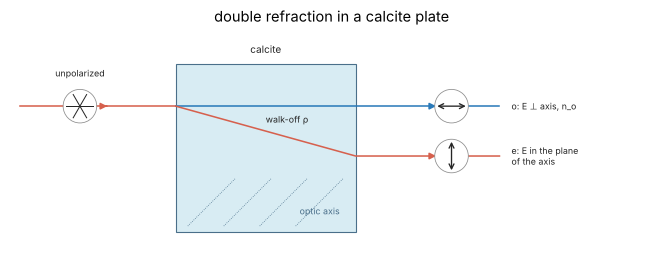

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sketch.crystal_optics_layout(ax, "calcite", title="double refraction in a calcite plate")
plt.show()

o: index 1.6583, power 0.469, Poynting vector at +0.00° to the normal
e: index 1.5664, power 0.476, Poynting vector at -6.24° to the normal
reflected: 0.055
image separation 0.109 mm per mm of calcite


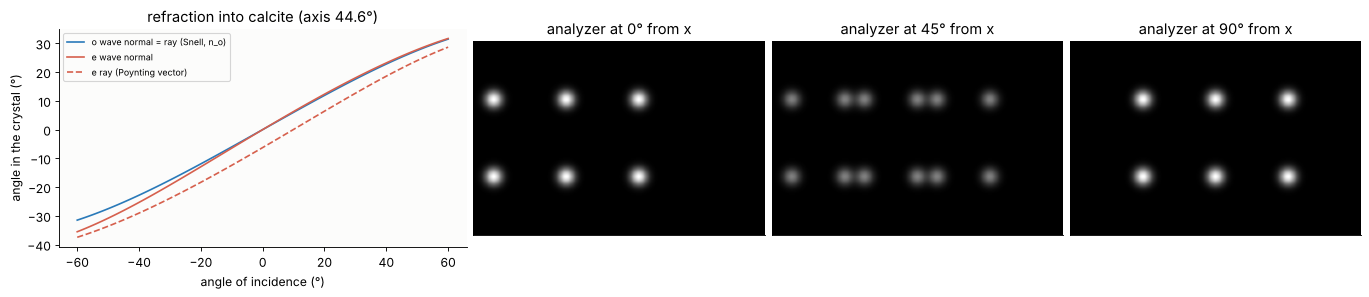

In [4]:
ax_rhomb = np.radians(44.6)
eps_cal = cr.uniaxial_eps(*n_cal, (np.sin(ax_rhomb), 0.0, np.cos(ax_rhomb)))
z = np.array([0.0, 0.0, 1.0])
tr, rf = cr.refract(1.0, eps_cal, z, z)
for w in tr:
    print("{}: index {:.4f}, power {:.3f}, Poynting vector at {:+.2f}° to the normal".format(
        w.label, np.linalg.norm(w.k), w.power, np.degrees(np.arctan2(w.S[0], w.S[2]))))
print("reflected: {:.3f}".format(sum(w.power for w in rf)))
shift = np.tan(np.radians(np.degrees(np.arctan2(*[w for w in tr if w.label == "e"][0].S[[0, 2]]))))
print("image separation {:.3f} mm per mm of calcite".format(abs(shift)))

# oblique incidence in the plane of the axis: wave normals and rays
thi = np.linspace(-60, 60, 121)
res = {"o": [], "e": [], "e ray": []}
for t in thi:
    k = np.array([np.sin(np.radians(t)), 0, np.cos(np.radians(t))])
    out = {w.label: w for w in cr.refract(1.0, eps_cal, z, k)[0]}
    res["o"].append(np.degrees(np.arctan2(out["o"].k[0], out["o"].k[2])))
    res["e"].append(np.degrees(np.arctan2(out["e"].k[0], out["e"].k[2])))
    res["e ray"].append(np.degrees(np.arctan2(out["e"].S[0], out["e"].S[2])))

# the double image of a dot pattern through a 10 mm rhomb, seen through an analyzer
d_plate = 10.0
xx, yy = np.meshgrid(np.linspace(-3, 3, 241), np.linspace(-2, 2, 161))
def dots(x0):
    return sum(np.exp(-((xx - x0 - cx)**2 + (yy - cy)**2)/0.03) for cx in (-1.5, 0, 1.5) for cy in (-0.8, 0.8))
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), layout="constrained",
                       gridspec_kw=dict(width_ratios=[1.4, 1, 1, 1]))
ax[0].plot(thi, res["o"], color=BLUE, label="o wave normal = ray (Snell, n_o)")
ax[0].plot(thi, res["e"], color=RED, label="e wave normal")
ax[0].plot(thi, res["e ray"], color=RED, ls="--", label="e ray (Poynting vector)")
ax[0].set_xlabel("angle of incidence (°)"); ax[0].set_ylabel("angle in the crystal (°)")
ax[0].legend(fontsize=8); ax[0].set_title("refraction into calcite (axis 44.6°)")
for a, ang in zip(ax[1:], (0, 45, 90)):
    A = np.radians(ang)
    # o polarized along y, e along x (in the plane of the axis)
    img = np.sin(A)**2*dots(0.0) + np.cos(A)**2*dots(d_plate*shift)
    a.imshow(img, cmap="gray", extent=(-3, 3, -2, 2), vmin=0, vmax=1)
    a.set_title(f"analyzer at {ang}° from x"); a.set_xticks([]); a.set_yticks([])
plt.show()

The ordinary wave obeys Snell's law with $n_o$. The extraordinary wave
normal obeys it too, but with the direction-dependent index, and its ray,
the dashed line, is not even on the same side of the normal at normal
incidence: at 0° the e ray leaves at 6.2°, and through a 10 mm rhomb the
two images of every dot are 1.1 mm apart. The images are polarized
orthogonally: an analyzer along $x$ (in the plane of the axis) shows
only the e image, one along $y$ only the o image, at 45° both at half
intensity. This is Bartholinus' observation of 1669 and Huygens'
explanation by an ellipsoidal wavelet; the reflection of the uncoated
surface is 3 % for o and 2.4 % for e light.

## 3. Wave plates at oblique incidence: the 4 × 4 matrix method

For layers parallel to the $x$–$y$ plane and a plane of incidence $x$–$z$,
the tangential fields $\psi = (E_x, H_y, E_y, H_x)$ obey Berreman's
equation $d\psi/dz = ik_0\Delta\psi$. The four eigenvalues of the 4 × 4
matrix $\Delta(\varepsilon, \xi)$, with the conserved
$\xi = n_\mathrm{in}\sin\theta$, are the normal components $k_z/k_0$ of
two forward and two backward waves, its eigenvectors their fields.
`cr.stack_jones()` multiplies the layers and matches the fields to the
isotropic media outside. Coherently (all reflections) it is the exact
solution; with `coherent=False` every interface transmits once (the
"extended Jones matrix" of Lien), which is what a thick plate in a beam of
finite bandwidth shows.

A quarter wave plate at 633 nm can be a **zero-order** quartz plate
($\delta = \pi/2$, 17 µm thick, usually two cemented plates) or a cheap
**multi-order** one ($\delta = 2\pi\cdot 10 + \pi/2$, 0.72 mm). Both are
quarter wave plates at normal incidence; the field of view and the
bandwidth are another matter.

zero order: 17.5 µm
multi-order (m = 10): 717.1 µm


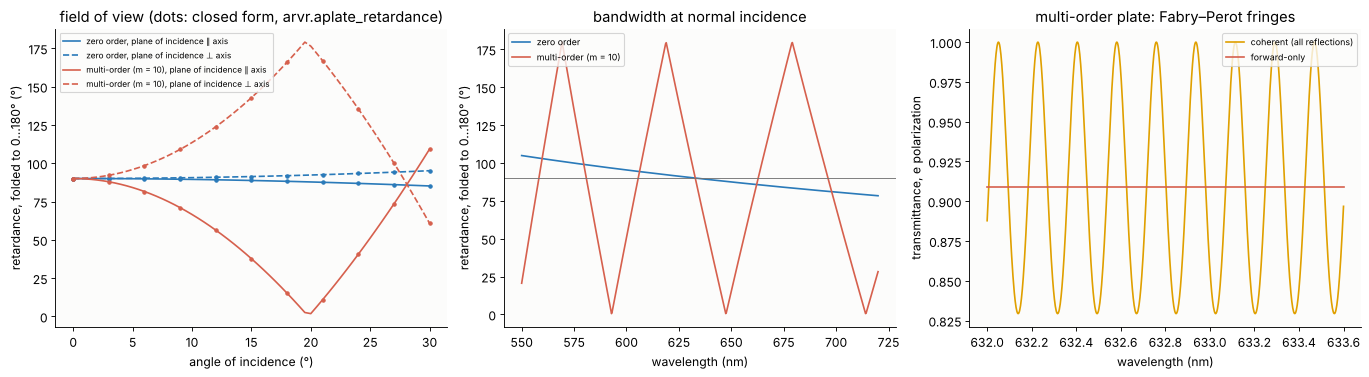

In [5]:
lam_um = 0.6328
nq_o, nq_e = cr.quartz_indices(632.8)
dn_q = nq_e - nq_o
plates = {"zero order": (0.25)*lam_um/dn_q, "multi-order (m = 10)": (10.25)*lam_um/dn_q}
eps_q = cr.uniaxial_eps(nq_o, nq_e, (1.0, 0.0, 0.0))     # A-plate, axis along x


def eigen_retardance(t):
    w = np.linalg.eigvals(t)
    r = np.angle(w[..., 1]/w[..., 0])
    return np.abs((r + np.pi) % (2*np.pi) - np.pi)


angles = np.linspace(0, 30, 61)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
for (name, d), c in zip(plates.items(), (BLUE, RED)):
    print("{}: {:.1f} µm".format(name, d))
    for psi, ls in ((0.0, "-"), (np.pi/2, "--")):
        xi = np.sin(np.radians(angles))
        t, _ = cr.stack_jones([(eps_q, d)], lam_um, xi, coherent=False, azimuth=psi)
        dl = eigen_retardance(t)
        ana = np.abs(((aplate_retardance(d, lam_um, nq_o, nq_e, xi, psi) + np.pi) % (2*np.pi)) - np.pi)
        ax[0].plot(angles, np.degrees(dl), color=c, ls=ls,
                   label="{}, plane of incidence {} axis".format(name, "∥" if psi == 0 else "⊥"))
        ax[0].plot(angles[::6], np.degrees(ana[::6]), "o", color=c, ms=3)
lam_s = np.linspace(0.55, 0.72, 600)
for (name, d), c in zip(plates.items(), (BLUE, RED)):
    no_s, ne_s = cr.quartz_indices(lam_s*1e3)
    tc, _ = cr.stack_jones([(cr.uniaxial_eps(no_s, ne_s, (1.0, 0.0, 0.0)), d)], lam_s, coherent=False)
    ax[1].plot(lam_s*1e3, np.degrees(eigen_retardance(tc)), color=c, label=name)
ax[1].axhline(90, color=GREY, lw=0.8)
# coherent: the multi-order plate as an uncoated etalon
lam_f = np.linspace(0.6320, 0.6336, 801)
no_f, ne_f = cr.quartz_indices(lam_f*1e3)
for coh, c, lab in ((True, ORANGE, "coherent (all reflections)"), (False, RED, "forward-only")):
    t, _ = cr.stack_jones([(cr.uniaxial_eps(no_f, ne_f, (1.0, 0.0, 0.0)), plates["multi-order (m = 10)"])],
                          lam_f, coherent=coh)
    ax[2].plot(lam_f*1e3, np.abs(t[..., 0, 0])**2, color=c, label=lab)
ax[0].set_xlabel("angle of incidence (°)"); ax[0].set_ylabel("retardance, folded to 0…180° (°)")
ax[0].set_title("field of view (dots: closed form, arvr.aplate_retardance)"); ax[0].legend(fontsize=7.5)
ax[1].set_xlabel("wavelength (nm)"); ax[1].set_ylabel("retardance, folded to 0…180° (°)"); ax[1].legend(fontsize=8)
ax[1].set_title("bandwidth at normal incidence")
ax[2].set_xlabel("wavelength (nm)"); ax[2].set_ylabel("transmittance, e polarization")
ax[2].set_title("multi-order plate: Fabry–Perot fringes"); ax[2].legend(fontsize=8)
plt.show()

The 4 × 4 method and the closed form for an A-plate
(`arvr.aplate_retardance`, dots) agree. The zero-order plate stays within
5° of 90° up to 30° incidence; the multi-order plate drifts by about
20° at 10° incidence, down when the plane of incidence contains the axis
and up perpendicular to it, it is a half wave or no retarder at all at
20°, and its retardance runs through a full turn between 590 and 650 nm
instead of changing slowly.
Multi-order plates are fine for a laser line and a collimated beam,
nothing else. Coherently the uncoated plate is also an etalon with a free
spectral range of 0.2 nm and 15 % peak-to-peak fringes, which the
forward-only calculation leaves out on purpose.

**Conoscopy.** Mineralogists look at a crystal plate between crossed
polarizers in a strongly converging beam. A plate cut perpendicular to the
optic axis (a C-plate) has no retardance on the axis, and away from it the
retardance grows with the square of the angle, the same in every
azimuth: dark rings where it is a multiple of $2\pi$. Where the plane of
incidence contains the polarizer or the analyzer, the eigenwaves are
along the polarizers and nothing passes: the dark cross (isogyres). Each
direction of the cone is one plane wave through the 4 × 4 method.

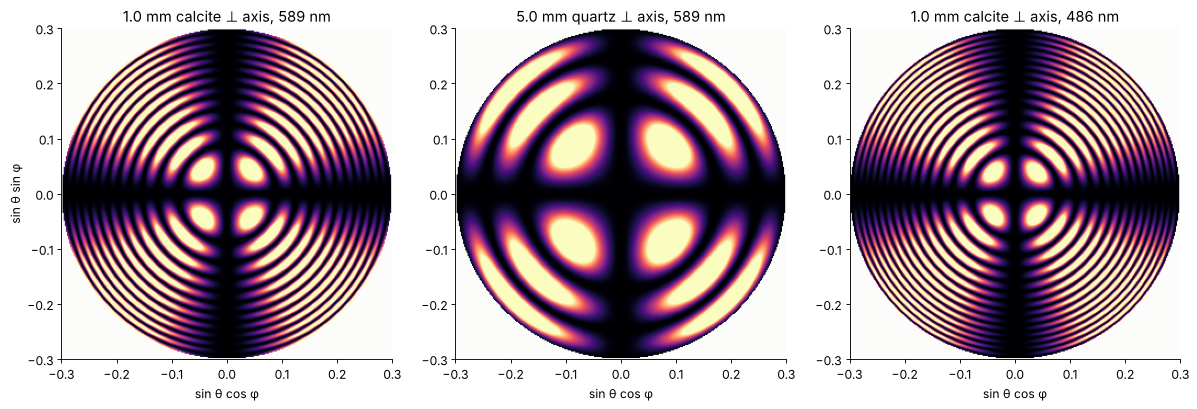

first dark ring of 1 mm calcite: sin θ ≈ n_o sqrt(λ/(d |Δn|)) = 0.097


In [6]:
N = 301
u = np.linspace(-0.3, 0.3, N)
UX, UY = np.meshgrid(u, u)
xi = np.hypot(UX, UY)
az = np.arctan2(UY, UX)
inside = xi < 0.3
fig, ax = plt.subplots(1, 3, figsize=(15, 4.9), layout="constrained")
for a, (d, mat, lam_c) in zip(ax, ((1.0, "calcite", 589.3), (5.0, "quartz", 589.3), (1.0, "calcite", 486.1))):
    n_oo, n_ee = cr.calcite_indices(lam_c) if mat == "calcite" else cr.quartz_indices(lam_c)
    eps_c = cr.uniaxial_eps(n_oo, n_ee, (0.0, 0.0, 1.0))
    t, _ = cr.stack_jones([(eps_c, d*1e3)], lam_c*1e-3, xi, coherent=False, azimuth=az)
    T = np.abs(t[..., 1, 0])**2*cr.power_factor(xi)
    T[~inside] = np.nan
    a.imshow(T, extent=(-0.3, 0.3, -0.3, 0.3), cmap="magma", origin="lower", vmin=0, vmax=0.5)
    a.set_title("{} mm {} ⊥ axis, {:.0f} nm".format(d, mat, lam_c)); a.set_xlabel("sin θ cos φ")
ax[0].set_ylabel("sin θ sin φ")
plt.show()
r1 = np.sqrt(589.3e-6/(1.0*abs(n_cal[1] - n_cal[0])))*n_cal[0]
print("first dark ring of 1 mm calcite: sin θ ≈ n_o sqrt(λ/(d |Δn|)) = {:.3f}".format(r1))

In 1 mm of calcite the first dark ring lies at $\sin\theta \approx 0.10$:
the retardance away from the axis is about
$\pi d\,|\Delta n|\sin^2\theta/(n_o^2\lambda)$ per $\pi$, so the $m$-th
ring grows as $\sqrt m$. Quartz has a twenty times weaker birefringence
and needs a thicker plate for the same pattern; a real quartz plate cut
perpendicular to the axis also rotates the plane of polarization on the
axis, which fills the centre of the cross (section 5, not included in the
tensor used here). Blue light has more rings, since the retardance scales
with $1/\lambda$. Conoscopic figures identify crystals and measure the
orientation of their axes, and the same calculation gives the field of
view of the Lyot filter in notebook 113 (Fabry–Perot and filters).

## 4. Polarizing prisms

A prism polarizer separates the two waves by angle instead of absorbing
one of them, and can take kilowatts. In a **Glan** polarizer two calcite
prisms face each other across a thin gap at the angle $\alpha$ to the
entrance face. The ordinary wave ($n_o = 1.658$) is totally reflected at
the gap if $n_o\sin\alpha > n_\mathrm{gap}$, the extraordinary one
($n_e = 1.486$) passes if $n_e\sin\alpha < n_\mathrm{gap}$. Rays tilted by a
few degrees move one of the two conditions past its limit: the field of
view. With the optic axis in the plane of incidence (Glan–Taylor) the
transmitted wave is p polarized at the gap and loses less than with the
axis perpendicular to it (Glan–Foucault). A cement of index 1.55 in the
gap (Glan–Thompson) needs a much flatter gap, a longer prism, and gives a
wider field. `cr.glan_prism()` traces all branches through the four
surfaces with the exact refraction of section 2.

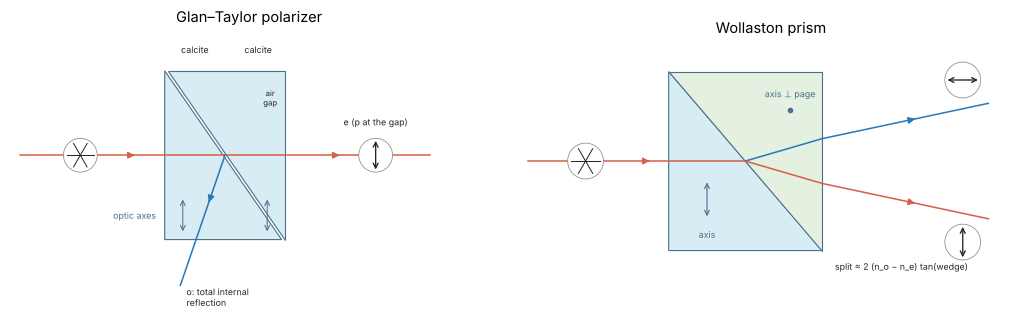

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
for a, k, t in zip(ax, ("glan_taylor", "wollaston"), ("Glan–Taylor polarizer", "Wollaston prism")):
    sketch.crystal_optics_layout(a, k, title=t)
plt.show()

Glan–Taylor, air, 38.5°            T_e(0) = 0.877, field of view -4.7° to +2.3°


Glan–Foucault, air, 38.5°          T_e(0) = 0.509, field of view -2.2° to +2.3°


Glan–Thompson, cement 1.55, 76°    T_e(0) = 0.834, field of view -13.1° to +11.3°


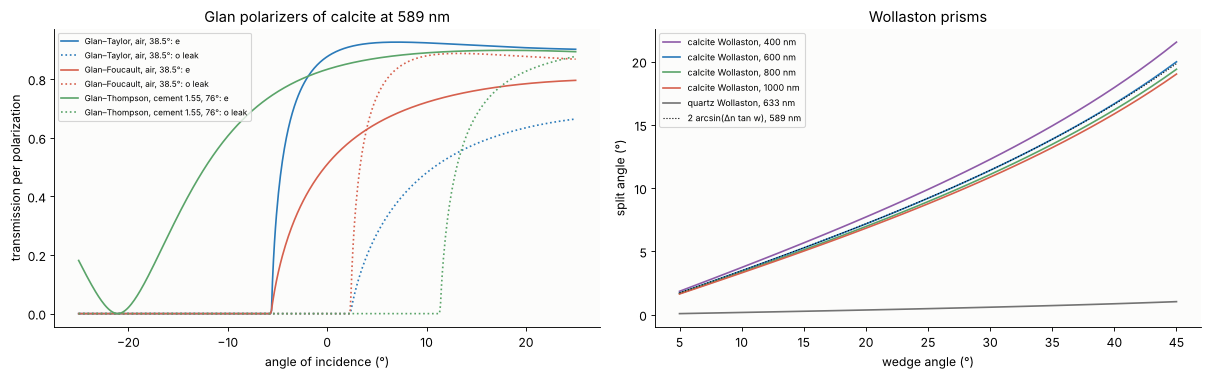

Rochon, wedge 20°: beam at -3.62°, power 0.450
Rochon, wedge 20°: beam at +0.00°, power 0.441


In [8]:
thg = np.linspace(-25, 25, 501)
designs = [("Glan–Taylor, air, 38.5°", 38.5, 1.0, "taylor", BLUE),
           ("Glan–Foucault, air, 38.5°", 38.5, 1.0, "foucault", RED),
           ("Glan–Thompson, cement 1.55, 76°", 76.0, 1.55, "foucault", GREEN)]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for name, apex, ng, axis, c in designs:
    Te, To = cr.glan_prism(thg, *n_cal, apex, n_gap=ng, axis=axis)
    ax[0].plot(thg, Te, color=c, label=name + ": e")
    ax[0].plot(thg, To, color=c, ls=":", label=name + ": o leak")
    good = (Te > 0.5*Te.max()) & (To < 1e-6)
    print("{:34s} T_e(0) = {:.3f}, field of view {:+.1f}° to {:+.1f}°".format(
        name, Te[thg == 0][0], thg[good].min(), thg[good].max()))
ax[0].set_xlabel("angle of incidence (°)"); ax[0].set_ylabel("transmission per polarization")
ax[0].legend(fontsize=7.5); ax[0].set_title("Glan polarizers of calcite at 589 nm")

wedges = np.linspace(5, 45, 41)
lam_w = np.linspace(400, 1000, 4)
for lw, c in zip(lam_w, (PURPLE, BLUE, GREEN, RED)):
    split = []
    for wd in wedges:
        ws = cr.wollaston(*cr.calcite_indices(lw), wd)
        a_ = [np.degrees(np.arctan2(w.k[0], w.k[2])) for w in ws]
        split.append(max(a_) - min(a_))
    ax[1].plot(wedges, split, color=c, label=f"calcite Wollaston, {lw:.0f} nm")
splitq = []
for wd in wedges:
    ws = cr.wollaston(*cr.quartz_indices(633.0), wd)
    a_ = [np.degrees(np.arctan2(w.k[0], w.k[2])) for w in ws]
    splitq.append(max(a_) - min(a_))
ax[1].plot(wedges, splitq, color=GREY, label="quartz Wollaston, 633 nm")
ax[1].plot(wedges, np.degrees(2*np.arcsin((n_cal[0] - n_cal[1])*np.tan(np.radians(wedges)))), "k:", lw=1,
           label="2 arcsin(Δn tan w), 589 nm")
ax[1].set_xlabel("wedge angle (°)"); ax[1].set_ylabel("split angle (°)"); ax[1].legend(fontsize=8)
ax[1].set_title("Wollaston prisms")
plt.show()
for wv in (cr.rochon(*n_cal, 20.0)):
    print("Rochon, wedge 20°: beam at {:+.2f}°, power {:.3f}".format(np.degrees(np.arctan2(wv.k[0], wv.k[2])), wv.power))

The Glan–Taylor accepts rays between −4.7° and +2.3°, a field of 7°: on
one side the e wave starts to be totally reflected too, on the other the
o wave escapes through the gap. It transmits 88 % of the e polarization
on the axis, the Glan–Foucault only 51 %, because there the e wave is s
polarized at the gap and reflects 26 % at each of its sides (both prisms
uncoated here); the strong reflection near the critical angle also
narrows its useful field to ±2.3°. The cemented Glan–Thompson, with its
gap at 76° (a prism four times longer than wide), accepts −13° to +11°,
at the price of length and of a cement that limits the power.

A **Wollaston** prism splits the beam symmetrically by about
$2\,\Delta n\tan w$: 7.2° for a 20° calcite wedge, with a mild
dispersion (calcite's birefringence falls from 0.19 at 400 nm to 0.17 at
1 µm). Quartz Wollastons split twenty times less and are used as shear
elements in DIC microscopes and interferometers. In a **Rochon** prism the
first half has its axis along the beam, so the o polarization passes
undeviated and achromatic, and only the e beam is deflected, by half the
Wollaston angle.

## 5. Optical activity

Quartz along its optic axis has no linear birefringence, but it rotates
the plane of polarization, by 21.7°/mm at 589 nm, clockwise for an
observer in right-handed quartz: the two circular polarizations have
slightly different indices. The rotation falls steeply with the
wavelength (rotatory dispersion, roughly as $1/\lambda^2$), so a plate
between polarizers transmits a colour that changes as the analyzer turns.
Natural optical activity is **reciprocal**: on the way back the light is
rotated back. Off the axis the linear birefringence grows as
$\Delta n\sin^2\theta$ and soon outweighs the circular one: the
eigenwaves become elliptical and then linear (Gouy). A homogeneous plate
with linear retardance $\delta$ and circular part $\rho d$ is
$\exp(N)$ with Jones' differential matrix $N$ (`cr.elliptical_retarder()`).

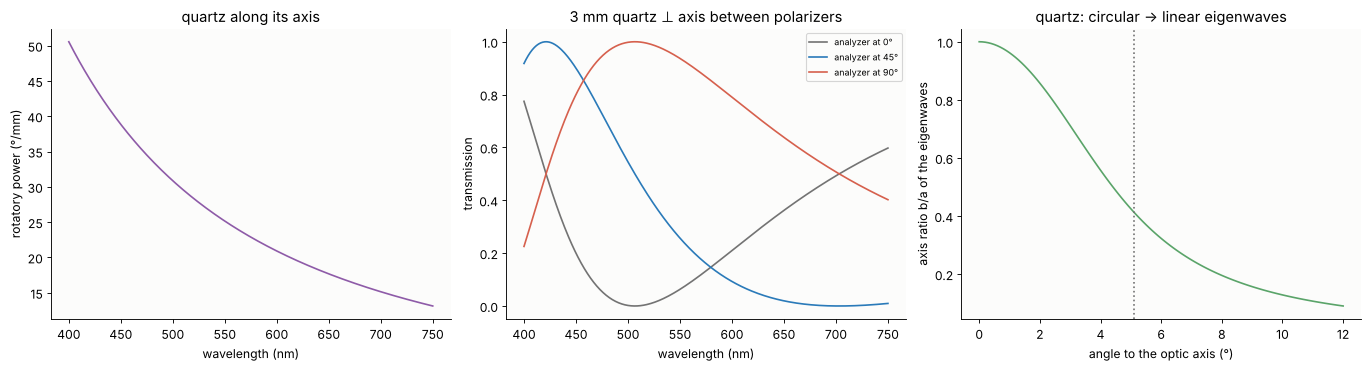

rotation 3 mm: 117° at 450 nm, 65° at 589 nm, 45° at 700 nm
linear and circular birefringence equal (axis ratio tan 22.5°) at 5.1° from the axis
round trip, natural activity:
 [[ 1. -0.]
 [-0.  1.]] 
round trip, Faraday 22.5° each way:
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]


In [9]:
lam_r = np.linspace(400, 750, 351)
rho = cr.quartz_rotatory_power(lam_r)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), layout="constrained")
ax[0].plot(lam_r, rho, color=PURPLE)
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("rotatory power (°/mm)")
ax[0].set_title("quartz along its axis")
d_q = 3.0                                              # mm
for an, c in ((0, GREY), (45, BLUE), (90, RED)):
    # right-handed quartz turns clockwise: -rho d in the convention of the module
    T = [abs(np.array([np.cos(np.radians(an)), np.sin(np.radians(an))]) @ cr.rotator(-np.radians(r*d_q))
             @ np.array([1.0, 0.0]))**2 for r in rho]
    ax[1].plot(lam_r, T, color=c, label=f"analyzer at {an}°")
ax[1].set_xlabel("wavelength (nm)"); ax[1].set_ylabel("transmission"); ax[1].legend(fontsize=8)
ax[1].set_title(f"{d_q:.0f} mm quartz ⊥ axis between polarizers")
# elliptical eigenwaves off the axis
thq = np.linspace(0, 12, 121)
nq_o5, nq_e5 = cr.quartz_indices(589.3)
ell = []
for t in np.radians(thq):
    dn_t = 1/np.sqrt(np.cos(t)**2/nq_o5**2 + np.sin(t)**2/nq_e5**2) - nq_o5
    delta = 2*np.pi*dn_t*1.0/589.3e-6                  # per mm
    J = cr.elliptical_retarder(delta, -np.radians(21.72)*1.0)
    w, v = np.linalg.eig(J)
    e = v[:, 0]
    # ellipticity tan(chi) from the Stokes parameters of the eigenvector
    S0 = np.sum(np.abs(e)**2)
    S3 = 2*np.imag(np.conj(e[0])*e[1])
    ell.append(np.tan(0.5*np.arcsin(abs(S3)/S0)))
ax[2].plot(thq, ell, color=GREEN)
cross = thq[np.argmin(np.abs(np.array(ell) - np.tan(np.pi/8)))]
ax[2].axvline(cross, color=GREY, ls=":")
ax[2].set_xlabel("angle to the optic axis (°)"); ax[2].set_ylabel("axis ratio b/a of the eigenwaves")
ax[2].set_title("quartz: circular → linear eigenwaves")
plt.show()
print("rotation 3 mm: {:.0f}° at 450 nm, {:.0f}° at 589 nm, {:.0f}° at 700 nm".format(
    *(cr.quartz_rotatory_power(np.array([450, 589.3, 700]))*d_q)))
print("linear and circular birefringence equal (axis ratio tan 22.5°) at {:.1f}° from the axis".format(cross))
# reciprocity: a round trip through an active plate and through a Faraday rotator
J_act = cr.rotator(-np.radians(21.72*3), backward=True) @ cr.rotator(-np.radians(21.72*3))
J_far = cr.rotator(np.radians(22.5), faraday=True, backward=True) @ cr.rotator(np.radians(22.5), faraday=True)
print("round trip, natural activity:\n", np.round(J_act, 6), "\nround trip, Faraday 22.5° each way:\n", np.round(J_far, 4))

3 mm of quartz rotates blue light at 450 nm by 117°, yellow by 65° and
red at 700 nm by 46°, so the transmitted spectrum is a broad band that
moves with the analyzer: this is how saccharimeters measured sugar
concentrations, and why quartz optics for polarized UV are cut slightly
off axis or made of two plates of opposite handedness. At 5° from the
axis the linear birefringence $\Delta n\sin^2\theta$ equals the circular
one and the eigenwaves have an axis ratio of 0.41; beyond about 10°
quartz behaves almost as an ordinary linear retarder. A round trip through
the active plate returns the original polarization exactly, whereas two
passes through a 22.5° Faraday rotator add up to 45°.

## 6. Faraday rotation and the optical isolator

A magnetic field $B$ along the beam rotates the plane of polarization by
$VBL$ (Verdet constant $V$), in the same sense with respect to the
field whatever the direction of the light. In the dielectric tensor the
magnetic field appears as an antisymmetric imaginary part,
$\varepsilon_{xy} = -\varepsilon_{yx} = ig$, which the 4 × 4 method takes as
it is (`cr.gyrotropic_eps()`). An **isolator** places a 45° rotator
between a polarizer and an analyzer at 45°: forward light passes, light
coming back is rotated by another 45° and stopped by the first polarizer.
Terbium gallium garnet (TGG), the standard crystal for 0.5 to 1.1 µm, has
$V = -40$ rad/(T m) at 1064 nm; $V$ falls with the wavelength roughly as
$1/(\lambda^2 - \lambda_0^2)$ and, as a paramagnet, as $1/T$.

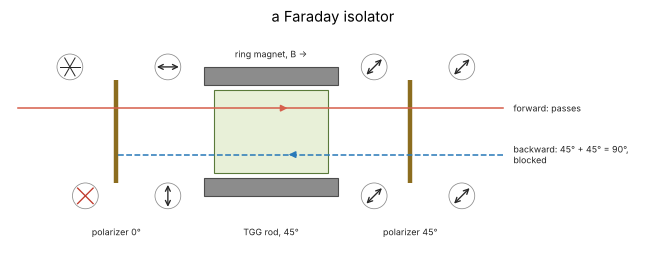

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.6))
sketch.crystal_optics_layout(ax, "isolator", title="a Faraday isolator")
plt.show()

TGG at 1064 nm: V = 40.0 rad/(T m), 45° needs 19.6 mm at 1 T
forward: x polarization leaves at 45.00° (lab frame)
backward: x polarization leaves at 45.00° (lab frame)


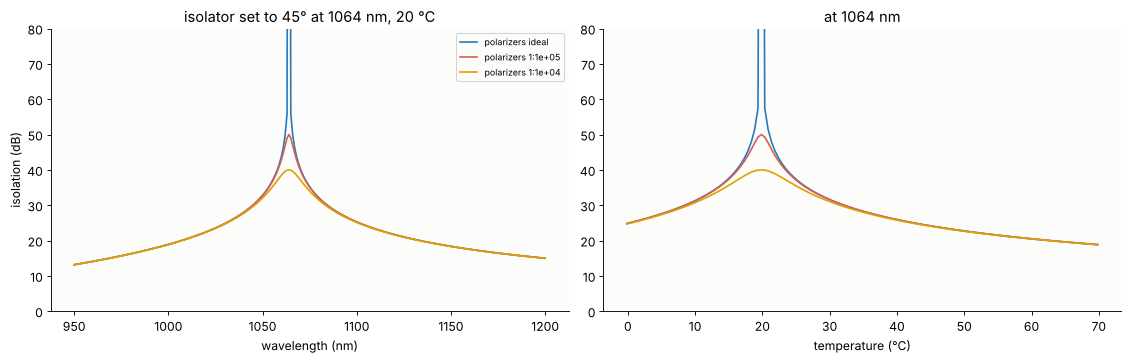

extinction inf: isolation 24.8 dB at 1030 nm, 25.3 dB at 1100 nm
extinction 100000.0: isolation 24.8 dB at 1030 nm, 25.2 dB at 1100 nm
+10 K: 31.6 dB, +20 K: 25.9 dB
30 dB or more from 1045 to 1084 nm and from 9 to 32 °C


In [11]:
n_tgg = 1.95
V1064 = abs(cr.tgg_verdet(1064.0))
B = 1.0                                               # T
L = np.pi/4/(V1064*B)                                 # m
print("TGG at 1064 nm: V = {:.1f} rad/(T m), 45° needs {:.1f} mm at 1 T".format(V1064, L*1e3))
# the rod in the 4 x 4 method: forward and backward
lam_m = 1.064e-6
g = cr.faraday_g(V1064*B, lam_m, n_tgg)
eps_tgg = cr.gyrotropic_eps(n_tgg**2*np.eye(3), g)
t_f, _ = cr.stack_jones([(eps_tgg, L)], lam_m, n_in=n_tgg, n_out=n_tgg, coherent=False)
flip = cr.rotation_matrix((1.0, 0, 0), np.pi)          # the same rod seen from the other side
t_b, _ = cr.stack_jones([(cr.rotate_eps(eps_tgg, flip), L)], lam_m, n_in=n_tgg, n_out=n_tgg, coherent=False)
t_b = np.diag([1, -1]) @ t_b @ np.diag([1, -1])       # back to the lab x-y frame
for name, t in (("forward", t_f), ("backward", t_b)):
    E = t @ np.array([1.0, 0.0])
    E = E/E[0]
    print("{}: x polarization leaves at {:.2f}° (lab frame)".format(name, np.degrees(np.arctan(E[1].real))))

lam_i = np.linspace(950, 1200, 251)
T_K = np.linspace(273, 343, 141)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), layout="constrained")
for ext, c in ((np.inf, BLUE), (1e5, RED), (1e4, ORANGE)):
    err = np.abs(cr.tgg_verdet(lam_i))*B*L - np.pi/4
    _, Tb = cr.isolator(err, extinction=ext)
    ax[0].plot(lam_i, -10*np.log10(Tb), color=c, label="polarizers " + ("ideal" if np.isinf(ext) else f"1:{ext:.0e}"))
    err_T = np.abs(cr.tgg_verdet(1064.0, T_K))*B*L - np.pi/4
    _, TbT = cr.isolator(err_T, extinction=ext)
    ax[1].plot(T_K - 273.15, -10*np.log10(TbT), color=c)
ax[0].set_ylim(0, 80); ax[1].set_ylim(0, 80)
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("isolation (dB)"); ax[0].legend(fontsize=8)
ax[0].set_title("isolator set to 45° at 1064 nm, 20 °C")
ax[1].set_xlabel("temperature (°C)"); ax[1].set_title("at 1064 nm")
plt.show()
for ext in (np.inf, 1e5):
    err = np.abs(cr.tgg_verdet(np.array([1030.0, 1100.0])))*B*L - np.pi/4
    print("extinction {}: isolation {:.1f} dB at 1030 nm, {:.1f} dB at 1100 nm".format(
        ext, *(-10*np.log10(cr.isolator(err, extinction=ext)[1]))))
errT = np.abs(cr.tgg_verdet(1064.0, np.array([303.15, 313.15])))*B*L - np.pi/4
print("+10 K: {:.1f} dB, +20 K: {:.1f} dB".format(*(-10*np.log10(cr.isolator(errT)[1]))))
iso_l = -10*np.log10(cr.isolator(np.abs(cr.tgg_verdet(lam_i))*B*L - np.pi/4)[1])
iso_T = -10*np.log10(cr.isolator(np.abs(cr.tgg_verdet(1064.0, T_K))*B*L - np.pi/4)[1])
print("30 dB or more from {:.0f} to {:.0f} nm and from {:.0f} to {:.0f} °C".format(
    lam_i[iso_l >= 30].min(), lam_i[iso_l >= 30].max(), T_K[iso_T >= 30].min() - 273.15, T_K[iso_T >= 30].max() - 273.15))

The 4 × 4 calculation of the magnetized rod reproduces the Faraday
rotation, and the light sent back through the same rod continues to turn
in the same sense: 45° on the way out, 90° after the round trip. A
19.6 mm TGG rod in a 1 T ring magnet makes a 1064 nm isolator. The
isolation is $-10\log_{10}\sin^2(\Delta\theta)$ for a rotation error
$\Delta\theta$, so it is high only in a narrow window: 30 dB requires the
rotation within 1.8°, which holds from 1045 to 1084 nm and from 9 to
32 °C for an isolator set up at 1064 nm and 20 °C. Polarizers with an extinction of $10^5$ cap the isolation at
50 dB, and high-isolation devices cascade two stages. Fibre isolators
for 1.55 µm use thin films of bismuth substituted iron garnets with
their own magnetization, and birefringent wedges instead of polarizers,
so that they work for any input polarization.

## Summary

- **Index ellipsoid:** the two waves for a direction are found from the
  section of the ellipsoid; the e wave walks off by up to 6.3° in calcite
  and 0.3° in quartz, its Poynting vector perpendicular to the index
  surface.
- **Double refraction:** at a surface the tangential wave vector is
  conserved; a 10 mm calcite rhomb separates the o and e images by
  1.1 mm, polarized orthogonally.
- **4 × 4 matrices:** exact for any stack of anisotropic layers,
  coherently or forward-only. A zero-order quartz quarter wave plate
  keeps its retardance over ±30°, a multi-order one only near normal
  incidence and one wavelength. A C-plate between crossed polarizers
  shows the conoscopic rings and cross.
- **Prism polarizers:** Glan–Taylor 88 % and a field of 7°;
  Glan–Thompson about 24° with cement; Wollaston split $2\Delta n\tan w$,
  Rochon with one undeviated beam.
- **Optical activity:** quartz rotates 21.7°/mm at 589 nm, reciprocally;
  5° off the axis its eigenwaves have an axis ratio of 0.41.
- **Faraday isolator:** non-reciprocal rotation, a 20 mm TGG rod at 1 T for
  1064 nm, 30 dB within about ±20 nm and ±11 K, limited by the
  polarizers' extinction.

In [12]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 12 s


## References

- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge
  University Press (1999), chapter 15.
- A. Yariv and P. Yeh, *Optical Waves in Crystals*, Wiley (1984).
- D. W. Berreman, "Optics in stratified and anisotropic media: 4 × 4-matrix
  formulation", J. Opt. Soc. Am. 62, 502–510 (1972).
- A. Lien, "Extended Jones matrix representation for the twisted nematic
  liquid-crystal display at oblique incidence", Appl. Phys. Lett. 57,
  2767–2769 (1990).
- J. M. Bennett, "Polarizers", in *Handbook of Optics*, Vol. II, 2nd ed.,
  McGraw-Hill (1995), chapter 3.
- G. Ghosh, "Dispersion-equation coefficients for the refractive index and
  birefringence of calcite and quartz crystals", Opt. Commun. 163, 95–102
  (1999).
- E. Hecht, *Optics*, 5th ed., Pearson (2017), chapter 8.